# Credit Risk Classification — Distributed Random Forest (PySpark / MLlib)

Originally developed and run on a Databricks single-node cluster (Runtime 12.2 LTS, Spark 3.3.2).
The `dbfs:/FileStore` paths below are Databricks-native; to run in a plain local/standalone Spark
session, point them at a local copy of `HPCI_Cleaned_Data.csv` instead (see
`data/sample/credit_risk_sample_200.csv` for a 200-row preview, or the root README for the full
dataset source). Cell outputs below are preserved from the original executed run.

In [0]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, rand, when
from pyspark.sql import Window
from pyspark.ml.feature import VectorAssembler, StringIndexer
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.sql.functions import udf
from pyspark.sql.types import DoubleType
import pyspark.sql.functions as F
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc as sk_auc, cohen_kappa_score, precision_recall_curve
import pandas as pd
import math
import os

# Ensure /dbfs/FileStore exists
os.makedirs("/dbfs/FileStore", exist_ok=True)

# Start Spark Session
spark = SparkSession.builder.appName("CreditRiskClassification").getOrCreate()

# Load the cleaned dataset from DBFS
df=spark.read.csv("dbfs:/FileStore/HPCI_Cleaned_Data.csv", header=True, inferSchema=True, nullValue="NA")

# Confirm schema of the dataset
df.printSchema()

root
 |-- Annual_Income: double (nullable = true)
 |-- Monthly_Inhand_Salary: double (nullable = true)
 |-- Num_Bank_Accounts: integer (nullable = true)
 |-- Num_Credit_Card: integer (nullable = true)
 |-- Interest_Rate: integer (nullable = true)
 |-- Num_of_Loan: integer (nullable = true)
 |-- Delay_from_due_date: integer (nullable = true)
 |-- Num_of_Delayed_Payment: integer (nullable = true)
 |-- Changed_Credit_Limit: double (nullable = true)
 |-- Num_Credit_Inquiries: integer (nullable = true)
 |-- Outstanding_Debt: double (nullable = true)
 |-- Total_EMI_per_month: double (nullable = true)
 |-- Amount_invested_monthly: double (nullable = true)
 |-- Credit_History_Months: integer (nullable = true)
 |-- Risk: integer (nullable = true)
 |-- OccupationAccountant: integer (nullable = true)
 |-- OccupationArchitect: integer (nullable = true)
 |-- OccupationDeveloper: integer (nullable = true)
 |-- OccupationDoctor: integer (nullable = true)
 |-- OccupationEngineer: integer (nullable = t

# Class Balancing & Train-Test Split (Manual & Controlled)
Ensure class balance in training set and evaluate model realistically with imbalanced test set.

In [0]:
# Check the class distribution
class_counts = df.groupBy("Risk").count().collect()
print("Original class distribution:")
for row in class_counts:
    print(f"Class {row[0]}: {row[1]} samples")

# Identify class labels
classes = [row[0] for row in class_counts]

train_dfs = []
test_dfs = []

for class_value in classes:
    class_df = df.filter(col("Risk") == class_value)
    class_count = class_df.count()
   
    # Finding the minimum class count
    min_class_count = min([row[1] for row in class_counts])
   
    # Undersample majority class
    if class_count > min_class_count:
        # Undersample to match minority class
        class_df = class_df.orderBy(rand(seed=42)).limit(min_class_count)
        class_count = min_class_count
   
     # Assign row numbers for reproducible split
    class_df = class_df.withColumn("row_num", F.row_number().over(Window.partitionBy("Risk").orderBy(rand(seed=42))))
   
    # Calculate split point (We are using 70% for training)
    train_count = int(class_count * 0.7)
   
    # Split into train and test
    train_class_df = class_df.filter(col("row_num") <= train_count).drop("row_num")
    test_class_df = class_df.filter(col("row_num") > train_count).drop("row_num")
   
    train_dfs.append(train_class_df)
    test_dfs.append(test_class_df)

# Merge all classes back
train_df = train_dfs[0]
for i in range(1, len(train_dfs)):
    train_df = train_df.union(train_dfs[i])

test_df = test_dfs[0]
for i in range(1, len(test_dfs)):
    test_df = test_df.union(test_dfs[i])

# Final shuffle
train_df = train_df.orderBy(rand(seed=42))
test_df = test_df.orderBy(rand(seed=42))

# Verifing the class distribution in train and test sets
print("\nTraining set class distribution:")
train_df.groupBy("Risk").count().show()

print("\nTest set class distribution:")
test_df.groupBy("Risk").count().show()

Original class distribution:
Class 1: 28998 samples
Class 0: 28998 samples

Training set class distribution:
+----+-----+
|Risk|count|
+----+-----+
|   1|20298|
|   0|20298|
+----+-----+


Test set class distribution:
+----+-----+
|Risk|count|
+----+-----+
|   1| 8700|
|   0| 8700|
+----+-----+



# Feature Assembly & Label Encoding
Convert features to vector format and categorical target to numeric label.

In [ ]:
label_indexer = StringIndexer(inputCol="Risk", outputCol="label")
label_indexer_model = label_indexer.fit(train_data)
train_data = label_indexer_model.transform(train_data)
test_data = label_indexer_model.transform(test_data)

In [ ]:
# Hardening check added for this repo (not part of the original executed run below):
# the confusion-matrix-derived metrics further down compare the raw "Risk" column
# directly against the classifier's "prediction" column, assuming StringIndexer's
# 0/1 label ordering matches Risk's own 0/1 coding. Assert that explicitly.
print("StringIndexer label mapping (index -> original Risk value):", label_indexer_model.labels)
assert label_indexer_model.labels[0] == "0" and label_indexer_model.labels[1] == "1", (
    "StringIndexer label order does not match raw Risk coding — "
    "downstream Risk == prediction comparisons would need remapping."
)

# Train Random Forest Model
Train a non-cross-validated Random Forest model with R-tuned hyperparameters.

In [0]:
# Random Forest Model
rf_model = RandomForestClassifier(
    labelCol="label",
    featuresCol="features",
    numTrees=1000,
    featureSubsetStrategy="8",  # Mimics mtry = 8 in R
    seed=42
)

rf_fitted = rf_model.fit(train_data)

# Evaluate Model – AUC & Accuracy
Quantify model's ROC AUC and raw classification accuracy.

In [0]:
# Predict on test set
predictions = rf_fitted.transform(test_data)

# AUC evaluator
evaluator = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="probability", metricName="areaUnderROC")
auc = evaluator.evaluate(predictions)
print(f"AUC: {auc:.4f}")

# Accuracy
accuracy = predictions.filter(predictions.Risk == predictions.prediction).count() / predictions.count()
print(f"Accuracy: {accuracy:.4f}")

AUC: 0.8460
Accuracy: 0.7856


# Confusion Matrix Metrics – Precision, Recall, F1, Specificity
Provide deeper insight beyond accuracy using clinical/classification evaluation metrics.


In [0]:

# Derive confusion matrix values
preds = predictions.withColumn("TP", when((col("Risk") == 1) & (col("prediction") == 1), 1).otherwise(0)) \
                   .withColumn("TN", when((col("Risk") == 0) & (col("prediction") == 0), 1).otherwise(0)) \
                   .withColumn("FP", when((col("Risk") == 0) & (col("prediction") == 1), 1).otherwise(0)) \
                   .withColumn("FN", when((col("Risk") == 1) & (col("prediction") == 0), 1).otherwise(0))

# Aggregate
agg = preds.selectExpr("sum(TP) as TP", "sum(TN) as TN", "sum(FP) as FP", "sum(FN) as FN").collect()[0]
TP, TN, FP, FN = agg["TP"], agg["TN"], agg["FP"], agg["FN"]

# Compute metrics
precision = TP / (TP + FP)
recall = TP / (TP + FN)
specificity = TN / (TN + FP)
f1 = 2 * (precision * recall) / (precision + recall)

print(f"Precision: {precision:.4f}")
print(f"Recall (Sensitivity): {recall:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"F1 Score: {f1:.4f}")

Precision: 0.8036
Recall (Sensitivity): 0.7560
Specificity: 0.8153
F1 Score: 0.7791


# Visualise ROC Curve
Visualize model performance with respect to trade-off between TPR and FPR

/databricks/spark/python/pyspark/sql/pandas/conversion.py:122: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  Unable to convert the field probability. If this column is not necessary, you may consider dropping it or converting to primitive type before the conversion.
Direct cause: Unsupported type in conversion to Arrow: VectorUDT()
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


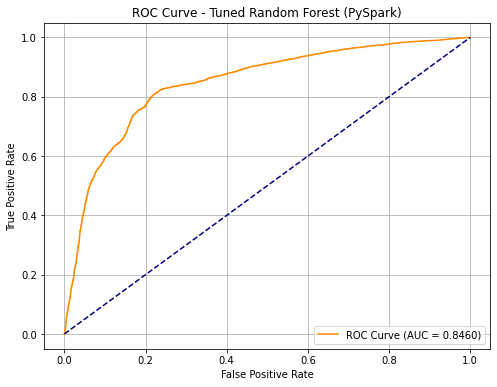

In [0]:

# Convert Spark predictions to pandas
roc_df = predictions.select("probability", "Risk").toPandas()
roc_df["probability"] = roc_df["probability"].apply(lambda x: float(x[1]))

# Compute ROC curve
fpr, tpr, _ = roc_curve(roc_df["Risk"], roc_df["probability"])
roc_auc = sk_auc(fpr, tpr)

# Plot
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.4f})", color='darkorange')
plt.plot([0,1], [0,1], color='navy', linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Random Forest (PySpark)")
plt.legend(loc="lower right")
plt.grid()
plt.savefig("/tmp/roc_curve.png")
dbutils.fs.cp("file:/tmp/roc_curve.png", "dbfs:/FileStore/roc_curve.png")
plt.show()

## Top 10 most important features 

In [0]:

# Get feature importances from the trained model
importances = rf_fitted.featureImportances

# Pair feature names with their importance scores
feature_importance_df = pd.DataFrame(
    list(zip(feature_cols, importances)),
    columns=["Feature", "Importance"]
)

# Sort and display top 10
top_10_features = feature_importance_df.sort_values(by="Importance", ascending=False).head(10)
print(top_10_features)

top_10_features.to_csv("/tmp/top_10_feature_importances.csv", index=False)
dbutils.fs.cp("file:/tmp/top_10_feature_importances.csv", "dbfs:/FileStore/top_10_feature_importances.csv")


                    Feature  Importance
10         Outstanding_Debt    0.304850
4             Interest_Rate    0.198978
9      Num_Credit_Inquiries    0.127602
6       Delay_from_due_date    0.084395
5               Num_of_Loan    0.055928
13    Credit_History_Months    0.052346
3           Num_Credit_Card    0.041212
29            Credit_MixBad    0.040204
2         Num_Bank_Accounts    0.028471
39  Payment_of_Min_AmountNo    0.013763
Out[8]: True

## Feature Importance Plot (Bar Chart)

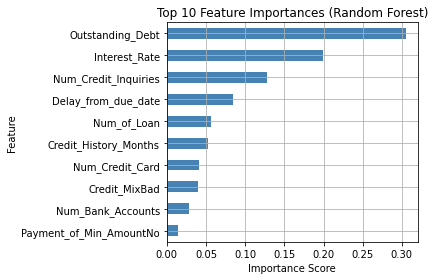

In [0]:
top_10_features.plot(kind="barh", x="Feature", y="Importance", legend=False, color="steelblue")
plt.gca().invert_yaxis()
plt.title("Top 10 Feature Importances (Random Forest)")
plt.xlabel("Importance Score")
plt.grid(True)
plt.tight_layout()
plt.savefig("/tmp/feature_importance_plot.png")
dbutils.fs.cp("file:/tmp/feature_importance_plot.png", "dbfs:/FileStore/feature_importance_plot.png")
plt.show()


## Confusion Matrix

In [0]:
conf_matrix = preds.groupBy("Risk", "prediction").count().orderBy("Risk", "prediction")
conf_matrix.show()

# Convert to Pandas for export
conf_matrix_pd = conf_matrix.toPandas()

# Add percentage of total
total = conf_matrix_pd["count"].sum()
conf_matrix_pd["percentage"] = (conf_matrix_pd["count"] / total * 100).round(2)

# Save to temporary location and move to DBFS
conf_matrix_pd.to_csv("/tmp/confusion_matrix.csv", index=False)
dbutils.fs.cp("file:/tmp/confusion_matrix.csv", "dbfs:/FileStore/confusion_matrix.csv")


+----+----------+-----+
|Risk|prediction|count|
+----+----------+-----+
|   0|       0.0| 7093|
|   0|       1.0| 1607|
|   1|       0.0| 2123|
|   1|       1.0| 6577|
+----+----------+-----+

Out[10]: True

## Balanced Accuracy

In [0]:
balanced_accuracy = (recall + specificity) / 2
print(f"Balanced Accuracy: {balanced_accuracy:.4f}")

Balanced Accuracy: 0.7856


## Matthews Correlation Coefficient (MCC)

In [0]:

mcc_numerator = (TP * TN) - (FP * FN)
mcc_denominator = math.sqrt((TP + FP)*(TP + FN)*(TN + FP)*(TN + FN))
mcc = mcc_numerator / mcc_denominator if mcc_denominator != 0 else 0
print(f"Matthews Correlation Coefficient (MCC): {mcc:.4f}")

Matthews Correlation Coefficient (MCC): 0.5723


## Precision-Recall (PR) Curve

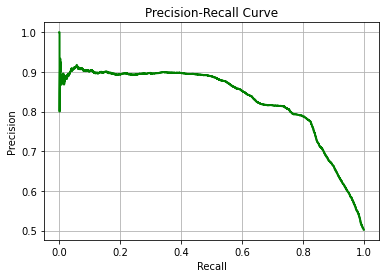

In [0]:

precision_vals, recall_vals, _ = precision_recall_curve(roc_df["Risk"], roc_df["probability"])
plt.plot(recall_vals, precision_vals, color="green", lw=2)
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.grid(True)
plt.savefig("/tmp/precision_recall_curve.png")
dbutils.fs.cp("file:/tmp/precision_recall_curve.png", "dbfs:/FileStore/precision_recall_curve.png")
plt.show()


## Kappa Statistic (Cohen’s Kappa)

In [0]:

# Kappa requires true labels and predictions
y_true = roc_df["Risk"]
y_pred = predictions.select("prediction").toPandas()

kappa = cohen_kappa_score(y_true, y_pred)
print(f"Cohen's Kappa: {kappa:.4f}")

Cohen's Kappa: 0.5713


## Gini Coefficient

In [0]:
gini = 2 * auc - 1
print(f"Gini Coefficient: {gini:.4f}")

Gini Coefficient: 0.6920


## Per-Class Metrics Table

In [0]:
# Format all percentage metrics (excluding AUC, Gini, MCC, Kappa)
accuracy_pct = accuracy * 100
precision_pct = precision * 100
recall_pct = recall * 100
specificity_pct = specificity * 100
f1_pct = f1 * 100
balanced_accuracy_pct = balanced_accuracy * 100

# Print formatted metrics
print(f"""
| Metric              | Value     |
|---------------------|-----------|
| AUC                 | {auc:.4f} |
| Gini Coefficient    | {gini:.4f} |
| Accuracy            | {accuracy_pct:.2f}% |
| Precision           | {precision_pct:.2f}% |
| Recall (Sensitivity)| {recall_pct:.2f}% |
| Specificity         | {specificity_pct:.2f}% |
| F1 Score            | {f1_pct:.2f}% |
| Balanced Accuracy   | {balanced_accuracy_pct:.2f}% |
| MCC                 | {mcc:.4f} |
| Kappa               | {kappa:.4f} |
""")

# Save metrics to CSV with percentage values
metrics_dict = {
    "AUC": [round(auc, 4)],
    "Gini": [round(gini, 4)],
    "Accuracy (%)": [round(accuracy_pct, 2)],
    "Precision (%)": [round(precision_pct, 2)],
    "Recall (Sensitivity) (%)": [round(recall_pct, 2)],
    "Specificity (%)": [round(specificity_pct, 2)],
    "F1 Score (%)": [round(f1_pct, 2)],
    "Balanced Accuracy (%)": [round(balanced_accuracy_pct, 2)],
    "MCC": [round(mcc, 4)],
    "Kappa": [round(kappa, 4)]
}

# Create DataFrame and save to FileStore
metrics_df = pd.DataFrame(metrics_dict)
metrics_df.to_csv("/tmp/evaluation_metrics.csv", index=False)
dbutils.fs.cp("file:/tmp/evaluation_metrics.csv", "dbfs:/FileStore/evaluation_metrics.csv")



| Metric              | Value     |
|---------------------|-----------|
| AUC                 | 0.8460 |
| Gini Coefficient    | 0.6920 |
| Accuracy            | 78.56% |
| Precision           | 80.36% |
| Recall (Sensitivity)| 75.60% |
| Specificity         | 81.53% |
| F1 Score            | 77.91% |
| Balanced Accuracy   | 78.56% |
| MCC                 | 0.5723 |
| Kappa               | 0.5713 |

Out[16]: True

### Save Model for Deployment & Export Predictions

In [0]:

# Get probability of class 1 from vector
get_prob = udf(lambda v: float(v[1]), DoubleType())
predictions_cleaned = predictions.withColumn("prob_class_1", get_prob(col("probability")))

# Drop complex fields
predictions_cleaned = predictions_cleaned.select("Risk", "prediction", "prob_class_1")

# Save predictions
predictions_cleaned.write.mode("overwrite").csv("dbfs:/FileStore/credit_predictions.csv", header=True)

# Save to CSV
predictions_cleaned.toPandas().to_csv("/dbfs/FileStore/credit_predictions.csv", index=False)